In [109]:
import numpy as np
import matplotlib.pyplot as plt

# Полиномиальная интерполяция Ньютона

In [110]:
def divided_difference(x, f):
    assert len(x) == len(f)

    x = np.asarray(x)
    f = np.asarray(f)

    assert x.ndim == 1 and f.ndim == 1

    if len(x) == 1:
        return f[0]

    return (divided_difference(x[1:], f[1:]) - divided_difference(x[:-1], f[:-1])
           ) / (x[-1] - x[0])

class NewtonInterpolation:
    def __init__(self, x, f):
        assert len(x) == len(f)
        x = np.asarray(x)
        f = np.asarray(f)
        assert x.ndim == 1 and f.ndim == 1

        n = x.shape[0]

        self.n = n
        self.x = x.copy()

        coefficients = f.astype(float).copy()
        for k in range(1, n):
            coefficients[k:] = ( coefficients[k:] - coefficients[k-1:-1]
                               ) / (x[k:] - x[:n-k])

        self.coefficients = coefficients

    def calculate(self, x):
        acc = self.coefficients[-1]

        for i in range(self.n - 2, -1, -1):
            acc = self.coefficients[i] + (x - self.x[i]) * acc

        return acc

# Решение трёхдиагональной системы

In [111]:

def solve_tridiagonal(a, b, c, d):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    c = np.asarray(c, dtype=float)
    d = np.asarray(d, dtype=float)

    n = len(b)
    assert n > 0
    assert len(a) == len(c) == len(d) == n

    alpha = np.zeros(n)
    beta = np.zeros(n)

    # Прямая прогонка
    if abs(b[0]) < 1e-14:
        raise ValueError("Zero or near-zero pivot")

    alpha[0] = -c[0] / b[0]
    beta[0] = d[0] / b[0]

    for i in range(1, n):
        q = b[i] + a[i] * alpha[i - 1]

        if abs(q) < 1e-14:
            raise ValueError("Zero or near-zero pivot")

        alpha[i] = -c[i] / q
        beta[i] = (d[i] - a[i] * beta[i - 1]) / q

    # Обратная прогонка
    x = np.zeros(n)
    x[-1] = beta[-1]

    for i in range(n - 2, -1, -1):
        x[i] = alpha[i] * x[i + 1] + beta[i]

    return x


# Естественный кубический сплайн

In [112]:
class CubicSplineInterpolation:
    def __init__(self, x, f):
        x = np.asarray(x, dtype=float)
        f = np.asarray(f, dtype=float)

        assert x.ndim == 1 and f.ndim == 1
        assert len(x) == len(f)
        assert len(x) >= 2
        assert np.all(np.diff(x) > 0)

        self.x = x.copy()
        n = len(x) - 1

        h = np.diff(x)
        delta = np.diff(f) / h

        # c_i = S''(x_i) / 2
        # Для естественного сплайна c_0 = c_n = 0
        c = np.zeros(n + 1)

        if n > 1:
            m = n - 1

            lower = np.zeros(m)
            diagonal = 2 * (h[:-1] + h[1:])
            upper = np.zeros(m)

            lower[1:] = h[1:-1]
            upper[:-1] = h[1:-1]

            rhs = 3 * (delta[1:] - delta[:-1])

            c[1:-1] = solve_tridiagonal(
                lower, diagonal, upper, rhs
            )

        # Коэффициенты на каждом промежутке
        self.a = f[:-1].copy()
        self.b = delta - h * (2*c[:-1] + c[1:]) / 3
        self.c = c[:-1].copy()
        self.d = (c[1:] - c[:-1]) / (3*h)

    def calculate(self, x):
        x = np.asarray(x, dtype=float)

        if np.any((x < self.x[0]) | (x > self.x[-1])):
            raise ValueError("Point is outside interpolation interval")

        # Находим промежуток, которому принадлежит x
        i = np.searchsorted(self.x, x, side="right") - 1
        i = np.clip(i, 0, len(self.a) - 1)

        t = x - self.x[i]

        result = (
            ((self.d[i] * t + self.c[i]) * t + self.b[i]) * t
            + self.a[i]
        )

        return float(result) if result.ndim == 0 else result

In [113]:

def solveGauss(A, b):
    n = len(b)

    A = [list(map(float, row)) for row in A]
    b = list(map(float, b))

    assert len(A) == n
    assert all(len(row) == n for row in A)

    # Прямой ход
    for k in range(n):
        # Выбор главного элемента по столбцу
        pivot = max(range(k, n), key=lambda i: abs(A[i][k]))

        if abs(A[pivot][k]) < 1e-12:
            raise ValueError("Matrix is singular or nearly singular")

        A[k], A[pivot] = A[pivot], A[k]
        b[k], b[pivot] = b[pivot], b[k]

        # Исключение переменной из нижних строк
        for i in range(k + 1, n):
            factor = A[i][k] / A[k][k]

            A[i][k] = 0.0
            for j in range(k + 1, n):
                A[i][j] -= factor * A[k][j]

            b[i] -= factor * b[k]

    # Обратный ход
    x = [0.0] * n

    for i in range(n - 1, -1, -1):
        s = b[i]

        for j in range(i + 1, n):
            s -= A[i][j] * x[j]

        x[i] = s / A[i][i]

    return x


class LeastSquaresApproximation:
    def __init__(self, x, f, basis):
        assert len(x) == len(f)
        assert len(x) > 0
        assert 0 < len(basis) <= len(x)

        self.basis = list(basis)

        m = len(x)
        n = len(basis)

        # Значения базисных функций в узлах
        phi = [
            [func(xi) for func in basis]
            for xi in x
        ]

        # Матрица нормальных уравнений и правая часть
        A = [[0.0] * n for _ in range(n)]
        b = [0.0] * n

        for j in range(n):
            for k in range(n):
                for i in range(m):
                    A[j][k] += phi[i][j] * phi[i][k]

            for i in range(m):
                b[j] += f[i] * phi[i][j]

        # Решение нормальных уравнений
        self.coefficients = solveGauss(A, b)

    def calculate(self, x):
        return sum(
            c * func(x)
            for c, func in zip(self.coefficients, self.basis)
        )

# Экстраполяция населения США

Newton: 827906509 человек, ошибка = 519160971 (168.152%)
Cubic Spline: 314133939 человек, ошибка = 5388401 (1.745%)
Least Squares: 309020979 человек, ошибка = 275441 (0.089%)


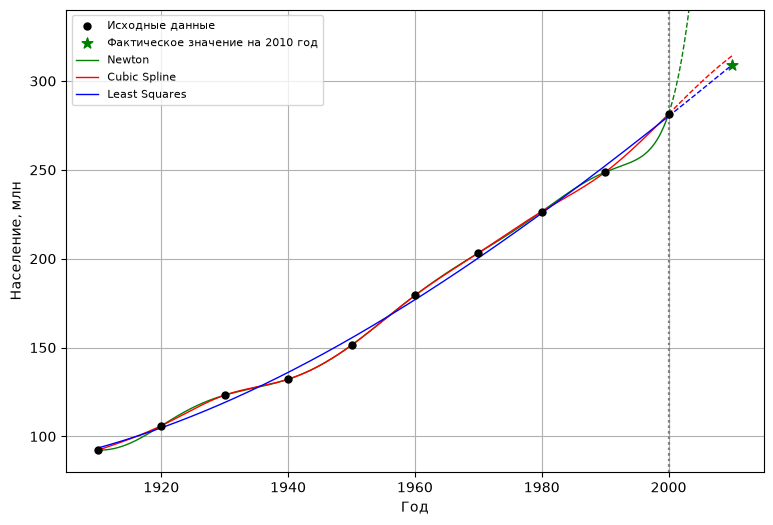

In [114]:
years = np.array([y for y in range(1910, 2000 + 1, 10)])
population = np.array([
    92228496,
    106021537,
    123202624,
    132164569,
    151325798,
    179323175,
    203211926,
    226545805,
    248709873,
    281421906,
], dtype=float)

actual_2010 = 308745538

# Нормируем аргумент и значения функции
t = (years - 1910) / 10
y = population / 1e6

# 1. Интерполяция Ньютона
newton = NewtonInterpolation(t, y)

# 2. Кубический сплайн
spline = CubicSplineInterpolation(t, y)

# 3. Метод наименьших квадратов
basis = [
    lambda x: 1,
    lambda x: x,
    lambda x: x**2,
    lambda x: x**3,
]
least_squares = LeastSquaresApproximation(t, y, basis)


def spline_calculate(t):
    # Внутри интервала используем обычный метод
    if t <= spline.x[-1]:
        return spline.calculate(t)

    # За пределами продолжаем последний полином
    i = len(spline.a) - 1
    dx = t - spline.x[i]

    return (
        spline.a[i]
        + spline.b[i] * dx
        + spline.c[i] * dx**2
        + spline.d[i] * dx**3
    )

methods = [
    ("Newton", newton.calculate),
    ("Cubic Spline", spline_calculate),
    ("Least Squares", least_squares.calculate),
]

# Сетка для графиков
t_inside = np.linspace(0, 9, 500)
t_outside = np.linspace(9, 10, 150)

plt.figure(figsize=(9, 6))

plt.scatter(years, y, color="black", s=25, zorder=3, label="Исходные данные")
plt.scatter([2010], [actual_2010 / 1e6], color="green", s=65, marker="*", zorder=4, label="Фактическое значение на 2010 год")

colors = ["green", "red", "blue"]

for (name, calculate), color in zip(methods, colors):
    y_inside = np.array([calculate(x) for x in t_inside])
    y_outside = np.array([calculate(x) for x in t_outside])

    prediction = calculate(10) * 1e6
    error = abs(prediction - actual_2010)
    relative_error = error / actual_2010 * 100

    plt.plot(1910 + 10 * t_inside, y_inside, label=f"{name}", linewidth=1, color=color)
    plt.plot(1910 + 10 * t_outside, y_outside, "--", linewidth=1, color=color)

    plt.grid(True)
    plt.axvline(2000, color="gray", linestyle=":")

    plt.xlabel("Год")
    plt.ylabel("Население, млн")
    plt.legend(fontsize=8)

    print(
        f"{name}: {prediction:.0f} человек, "
        f"ошибка = {error:.0f} ({relative_error:.3f}%)"
    )

plt.xlim(1905, 2015)
plt.ylim(80, 340)

plt.show()